In [1]:
# 錄製檔切分
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import json
from collections import deque
from collections.abc import Mapping
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.csv as pacsv

# 訓練模型
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import copy
from tqdm import tqdm

## 2. 讀取dataset： `(N Breath, 3, 256)`

In [3]:
L = 256
CH = ["Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)"]
# 第二輪資料（prosses_data_round2 剔除後的）
CACHE = rf"D:\pva_training\data\training_data\1to4_PC-AC_L{L}_stage2_remove16"

X = np.load(os.path.join(CACHE, "X.npy"), mmap_mode="r")      # 不加 mmap_mode 就整個讀進記憶體
kb = pd.read_csv(os.path.join(CACHE, "kb.csv"), dtype={"rec": str, "mode": str})
dropped = pd.read_csv(os.path.join(CACHE, "dropped.csv"), dtype={"rec": str})
ids = list(zip(kb["rec"], kb["breath_id"]))
lens = kb["points"].to_numpy()
print("X shape =", X.shape)

X shape = (755672, 3, 256)


## 3. 切訓練集 80% / 驗證集 20%

In [4]:
# seed=0, 隨機打散X排序
rng = np.random.default_rng(0)
perm = rng.permutation(len(X))

# 20% n 當作 val
n_val = int(len(X) * 0.2)

# 前20% val, 後80% train
va_idx, tr_idx = perm[:n_val], perm[n_val:]
print("train", X[tr_idx].shape)
print("val  ", X[va_idx].shape)

train (604538, 3, 256)
val   (151134, 3, 256)


## 4. 標準化（z-score）
不用 min-max 的原因：
1. min-max 容易被極值影響
2. Pressure、Volume 從 0 往上，Flow 有正有負

In [5]:
# Standardization (z-score)： 
mean = X[tr_idx].mean(axis=(0, 2), keepdims=True)        # shape (1, 3, 1)：每個通道一個平均
std  = X[tr_idx].std(axis=(0, 2), keepdims=True) + 1e-6

# x' = (x - mean) / std
Xn = (X - mean) / std

# 轉成torch格式
X_tr = torch.from_numpy(Xn[tr_idx])
X_va = torch.from_numpy(Xn[va_idx])
print("train", X_tr.shape)
print("val  ", X_va.shape)

train torch.Size([604538, 3, 256])
val   torch.Size([151134, 3, 256])


## 5. 建模型

In [6]:
# resampling後，共3*256=768，latent壓縮成16，這樣是48倍壓縮
LATENT = 16 

class ConvAE(nn.Module):
    def __init__(self, in_ch=3, L=L, latent=LATENT):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(in_ch, 16, 7, stride=2, padding=3), nn.ReLU(),   # (N,  3, 256)  -> (N, 16, 128)
            nn.Conv1d(16, 32, 7, stride=2, padding=3), nn.ReLU(),      # (N, 16, 128)  -> (N, 32,  64)
            nn.Conv1d(32, 64, 7, stride=2, padding=3), nn.ReLU(),      # (N, 32,  64)  -> (N, 64,  32)
            nn.Flatten(),                                              # 64*32 = 2048
            nn.Linear(64 * (L // 8), latent),                          # 64*(32)-> latent
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent, 64 * (L // 8)), nn.ReLU(),                    # 64*(32)-> latent
            nn.Unflatten(1, (64, L // 8)),                                  # 64*32 = 2048
            nn.ConvTranspose1d(64, 32, 4, stride=2, padding=1), nn.ReLU(),  # (N, 64,  32)  -> (N, 32,  64)
            nn.ConvTranspose1d(32, 16, 4, stride=2, padding=1), nn.ReLU(),  # (N, 64,  32)  -> (N, 16, 128)
            nn.ConvTranspose1d(16, in_ch, 4, stride=2, padding=1),          # (N, 16, 128)  -> (N,  3, 256)
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)
        
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_tr = X_tr.to(device)
X_va = X_va.to(device)

model = ConvAE().to(device)
print(model(X_tr[:2]).shape)   # 應該要是 [2, 3, 256]，跟輸入一樣
print(device)                                  # cuda 或 cpu

torch.Size([2, 3, 256])
cuda


## 6. 訓練

epoch   0  lr 3.0e-04  train 0.06800  val 0.01437  * best


epoch   1  lr 3.0e-04  train 0.01177  val 0.01028  * best


epoch   2  lr 3.0e-04  train 0.00925  val 0.00847  * best


epoch   3  lr 3.0e-04  train 0.00811  val 0.00874  (no improvement 1/20)


epoch   4  lr 3.0e-04  train 0.00734  val 0.00729  * best


epoch   5  lr 3.0e-04  train 0.00688  val 0.00690  * best


... (123 outputs left out)

epoch 129  lr 1.0e-05  train 0.00340  val 0.00356  (no improvement 17/20)


epoch 130  lr 1.0e-05  train 0.00340  val 0.00356  (no improvement 18/20)


epoch 131  lr 1.0e-05  train 0.00340  val 0.00356  (no improvement 19/20)


epoch 132  lr 1.0e-05  train 0.00340  val 0.00356  (no improvement 20/20)

Early stop at epoch 132
Using epoch 112 model, best val = 0.00356


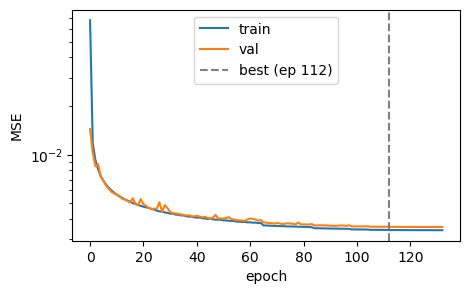

In [7]:
torch.manual_seed(0)
opt = torch.optim.Adam(model.parameters(), lr=3e-4)        # model 搬到 GPU 之後再建 optimizer
loss_fn = nn.MSELoss()
loader = torch.utils.data.DataLoader(X_tr, batch_size=256, shuffle=True)

MAX_EPOCHS = 300
PATIENCE   = 20
MIN_DELTA  = 1e-5

# val 沒進步就降 lr
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    opt,
    mode="min",
    factor=0.5,
    patience=5,
    threshold=MIN_DELTA,
    threshold_mode="abs",
    min_lr=1e-5,
)

hist = {"train": [], "val": []}
best_val, best_ep, best_state, wait = float("inf"), -1, None, 0

# 開始training
for ep in range(MAX_EPOCHS):
    model.train()
    tot, seen = 0, 0
    bar = tqdm(loader, desc=f"epoch {ep:3d}", leave=False)      # 這個epoch進度條
    for x in bar:
        loss = loss_fn(model(x), x)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(x); seen += len(x)
        bar.set_postfix(loss=f"{tot / seen:.5f}")              # 顯示目前的平均 loss
    tr = tot / len(X_tr)

    model.eval()
    with torch.no_grad():
        va = loss_fn(model(X_va), X_va).item()
    hist["train"].append(tr); hist["val"].append(va)

    lr_now = opt.param_groups[0]["lr"]                         # 這個 epoch 的 lr
    scheduler.step(va)                                         # 依 val loss 調 lr

    if va < best_val - MIN_DELTA:
        best_val, best_ep, wait = va, ep, 0
        best_state = copy.deepcopy(model.state_dict())
        mark = "  * best"
    else:
        wait += 1
        mark = f"  (no improvement {wait}/{PATIENCE})"
    print(f"epoch {ep:3d}  lr {lr_now:.1e}  train {tr:.5f}  val {va:.5f}{mark}")

    if wait >= PATIENCE:
        print(f"\nEarly stop at epoch {ep}")
        break

model.load_state_dict(best_state)
print(f"Using epoch {best_ep} model, best val = {best_val:.5f}")

plt.figure(figsize=(5, 3))
plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="val")
plt.axvline(best_ep, color="gray", ls="--", label=f"best (ep {best_ep})")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

In [8]:
# 儲存模型
SAVE_DIR = "checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)
SAVE_PATH = os.path.join(SAVE_DIR, f"1to4_ae_latent{LATENT}_round2_remove16.pt")

torch.save({
    "model_state": model.state_dict(),   # 這時已經是 best_state 的權重
    "opt_state":   opt.state_dict(),     # 接著訓練才會用到
    "best_ep":     best_ep,
    "best_val":    best_val,
    "hist":        hist,
}, SAVE_PATH)

print(f"Saved to {SAVE_PATH}")

Saved to checkpoints\1to4_ae_latent16_round2_remove16.pt


## 7. 看還原效果

In [9]:
# 載入模型
SAVE_PATH = f"checkpoints/1to4_ae_latent{LATENT}_round2_remove16.pt"
device = "cuda" if torch.cuda.is_available() else "cpu"

ckpt = torch.load(SAVE_PATH, map_location=device)

model = ConvAE().to(device)              # 要先跑過上面 ConvAE 的定義
model.load_state_dict(ckpt["model_state"])
model.eval()                             # eval 模式

print(f"Loaded epoch {ckpt['best_ep']} model, best val = {ckpt['best_val']:.5f}")

# 推論範例
with torch.no_grad():
    recon = model(X_va.to(device))
    err = ((recon - X_va.to(device)) ** 2).mean(dim=tuple(range(1, X_va.ndim)))  # 每口的重建誤差

Loaded epoch 112 model, best val = 0.00356


In [10]:
def reconstruct(k):
    """第 k 口的 (原始, 還原)，已換回原本單位"""
    model.eval()
    with torch.no_grad():
        out = model(torch.from_numpy(Xn[k:k+1]).float()).numpy()
    return X[k], (out * std + mean)[0]

def plot_recon(k):
    bid = ids[k]                                  # 只拿來顯示
    x, xh = reconstruct(k)
    fig, ax = plt.subplots(3, 1, figsize=(7, 5), sharex=True)
    for i, name in enumerate(CH):
        ax[i].plot(x[i], label="original"); ax[i].plot(xh[i], "--", label="reconstructed")
        ax[i].set_ylabel(name)
    ax[0].set_title(f"Breath {bid}   score={scores[k]:.3f}"); ax[0].legend()
    ax[-1].set_xlabel(f"resampled point (0..{L-1})")
    plt.tight_layout(); plt.show()

## 8. 還原誤差當異常分數

每口算一個 MSE。大部分呼吸是正常的，模型學到的是正常的樣子，分數特別高的可以當 PVA 候選。

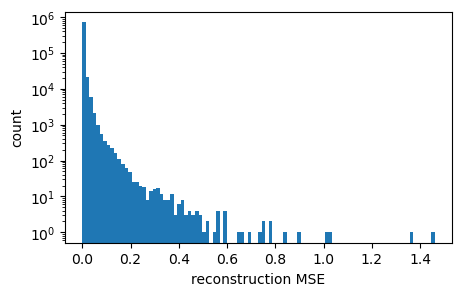

分數最高的 10 口： [['1', '86334'], ['2', '256565'], ['2', '244072'], ['4', '175039'], ['1', '88732'], ['1', '62854'], ['2', '258812'], ['1', '1655'], ['1', '112833'], ['2', '517538']]
分數最低的 5 口： [['2', '396400'], ['2', '395509'], ['2', '396532'], ['2', '396448'], ['2', '318028']]


In [11]:
model = model.cpu()
model.eval()

scores_list, Z_list = [], []
with torch.no_grad():
    for i in range(0, len(Xn), 1024):
        xb = torch.from_numpy(Xn[i:i+1024]).float()
        scores_list.append(((model(xb) - xb) ** 2).mean(dim=(1, 2)))
        Z_list.append(model.encoder(xb))
scores = torch.cat(scores_list).numpy()
Z = torch.cat(Z_list).numpy()  

plt.figure(figsize=(5, 3))
plt.hist(scores, bins=100); plt.yscale("log")
plt.xlabel("reconstruction MSE"); plt.ylabel("count"); plt.show()
ids = np.asarray(ids)

order = np.argsort(scores)[::-1]
print("分數最高的 10 口：", ids[order[:10]].tolist())
print("分數最低的 5 口：", ids[order[-5:]].tolist())

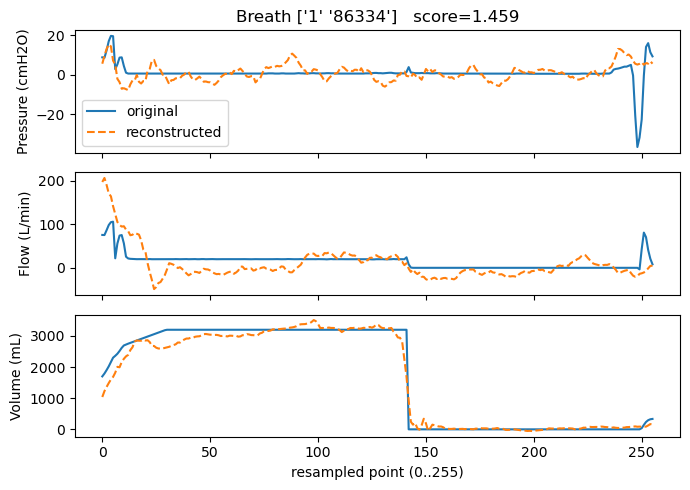

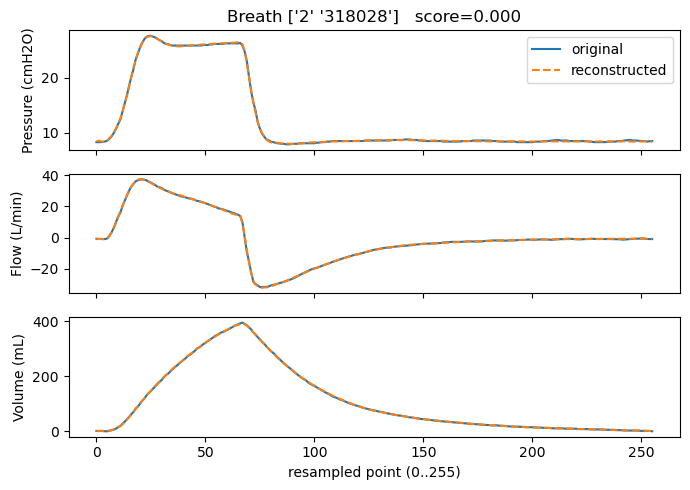

In [12]:
plot_recon(order[0])     # 最異常的一口
plot_recon(order[-1])    # 最正常的一口